# PathSnap Extra Trees · Shared6

Train and evaluate Extra Trees on `PathSnap_shared6.zip` in a new Colab notebook. A CPU runtime is sufficient.

The dataset already contains prepared candidates, six feature columns, provisional labels, and five fixed trip folds. The Shared6 pipeline generated up to 8 candidates within 75 m. It also supplies an observation ledger so GPS points with zero candidates remain in the Top-1 denominator.

For a Drive file from **Shared with me**, add a shortcut to the `PathSnap_ip` folder in **My Drive**. If you add the ZIP itself to My Drive, the setup also checks there. Alternatively, upload the ZIP through the Colab Files panel and set `USE_DRIVE = False`.


## 1. Mount Drive and extract the prepared dataset

In [1]:
from pathlib import Path
import hashlib
import json
import shutil
import zipfile

# Set False if you upload PathSnap_shared6.zip directly to Colab's Files panel.
USE_DRIVE = True
RUNTIME_DIR = Path("/content")
ZIP_NAME = "PathSnap_shared6.zip"
DRIVE_ZIP = Path("/content/drive/MyDrive/PathSnap_ip") / ZIP_NAME

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    drive_alternatives = (DRIVE_ZIP, Path("/content/drive/MyDrive") / ZIP_NAME)
    zip_path = next((path for path in drive_alternatives if path.is_file()), None)
    if zip_path is None:
        raise FileNotFoundError(
            "Add a shortcut to the PathSnap_ip folder (or the ZIP itself) in My Drive, "
            "then rerun. If you upload the ZIP to Colab's Files panel, set USE_DRIVE=False."
        )
else:
    zip_path = RUNTIME_DIR / ZIP_NAME

if not zip_path.is_file():
    raise FileNotFoundError(f"Dataset ZIP not found: {zip_path}")

WORK_DIR = RUNTIME_DIR / "pathsnap_shared6_extra_trees"
DATA_DIR = WORK_DIR / "input"
RESULTS_DIR = WORK_DIR / "results"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

local_zip = WORK_DIR / ZIP_NAME
shutil.copyfile(zip_path, local_zip)
with local_zip.open("rb") as source:
    dataset_hash = hashlib.file_digest(source, "sha256").hexdigest()

required = {
    "shared_protocol.json", "feature_schema.json", "cache_manifest.json",
    "fold_assignments.csv", "train_features.npz", "train_observations.csv.gz",
    "student_test_features.npz", "student_test_observations.csv.gz",
} | {f"fold_{i}_indices.npz" for i in range(1, 6)}
with zipfile.ZipFile(local_zip) as archive:
    missing = required - set(archive.namelist())
    if missing:
        raise ValueError(f"Unexpected dataset ZIP. Missing: {sorted(missing)}")
    for filename in sorted(required):
        with archive.open(filename) as src, (DATA_DIR / filename).open("wb") as dst:
            shutil.copyfileobj(src, dst)

print(f"Dataset ready: {zip_path}")
print(f"Extracted files: {DATA_DIR}")


Mounted at /content/drive
Dataset ready: /content/drive/MyDrive/PathSnap_ip/PathSnap_shared6.zip
Extracted files: /content/pathsnap_shared6_extra_trees/input


## 2. Load the training matrix and validate the trip assignments

The six inputs, in archive order, are distance, distance rank, heading difference, projection fraction, segment length, and displacement. Trip and observation IDs are for evaluation. They are kept outside the feature matrix.


In [2]:
from dataclasses import dataclass
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, log_loss, precision_score, recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

protocol = json.loads((DATA_DIR / "shared_protocol.json").read_text())
manifest = json.loads((DATA_DIR / "cache_manifest.json").read_text())
schema = json.loads((DATA_DIR / "feature_schema.json").read_text())
FEATURES = [item["name"] for item in schema]
if FEATURES != protocol["features"] or len(FEATURES) != 6:
    raise ValueError("Feature order differs from the six-feature protocol.")
RANK_COL = FEATURES.index("distance_rank")
SEED = int(manifest["protocol"]["random_state"])

# The shared protocol standardizes inputs. Each scaler is fitted only on
# the relevant training rows, and the saved model includes its final scaler.
USE_SCALING = True
MODEL_PARAMS = {
    "n_estimators": 48,
    "max_depth": 16,
    "min_samples_leaf": 6,
    "max_features": "sqrt",
    "random_state": SEED,
    "n_jobs": 2,
}
KEYS = ["trip_id", "observation_id"]


@dataclass
class Dataset:
    X: np.ndarray
    y: np.ndarray
    trip_ids: np.ndarray
    arcs: np.ndarray
    obs_index: np.ndarray
    observations: pd.DataFrame


def load_split(split):
    with np.load(DATA_DIR / f"{split}_features.npz", allow_pickle=False) as data:
        X, y = data["X"], data["label"]
        trip_ids, obs_ids, arcs = data["trip_id"], data["observation_id"], data["arc_id"]
    obs = pd.read_csv(
        DATA_DIR / f"{split}_observations.csv.gz",
        dtype={"trip_id": str, "reference_present": bool},
        usecols=KEYS + ["reference_arc_id", "candidate_count", "reference_present"],
    )
    index = pd.MultiIndex.from_frame(obs[KEYS])
    obs_index = index.get_indexer(pd.MultiIndex.from_arrays([trip_ids, obs_ids]))
    if X.shape != (len(y), len(FEATURES)) or not np.isfinite(X).all():
        raise ValueError(f"Invalid features in {split}")
    if (obs_index < 0).any() or not np.isin(y, [0, 1]).all():
        raise ValueError(f"Invalid candidate keys or labels in {split}")
    counts = np.bincount(obs_index, minlength=len(obs))
    ref_arcs = obs["reference_arc_id"].to_numpy()
    positives = arcs == ref_arcs[obs_index]
    covered = np.bincount(obs_index[positives], minlength=len(obs)) > 0
    if (not np.array_equal(positives, y)
            or not np.array_equal(counts, obs["candidate_count"])
            or not np.array_equal(covered, obs["reference_present"])):
        raise ValueError(f"Candidate file and observation ledger disagree for {split}")
    return Dataset(X, y, trip_ids, arcs, obs_index, obs)


train = load_split("train")
fold_assignment = pd.read_csv(DATA_DIR / "fold_assignments.csv", dtype={"trip_id": str})
fold_by_trip = fold_assignment.set_index("trip_id")["fold"]
folds = sorted(fold_by_trip.unique())
if (not fold_by_trip.index.is_unique or folds != [1, 2, 3, 4, 5]
        or len(fold_by_trip) != 80
        or set(fold_by_trip.index) != set(train.observations["trip_id"])
        or len(train.y) != protocol["train_candidates"]):
    raise ValueError("Training dataset does not match the supplied five trip folds.")
train_obs_folds = train.observations["trip_id"].map(fold_by_trip).to_numpy()
train_row_folds = train_obs_folds[train.obs_index]

print(f"{len(fold_by_trip)} training trips | {len(train.observations):,} GPS points | "
      f"{len(train.y):,} candidate rows")
print("Features:", ", ".join(FEATURES))
print("Scikit-learn:", sklearn.__version__)
display(pd.DataFrame(train.X[:5], columns=FEATURES).assign(label=train.y[:5]))


80 training trips | 208,417 GPS points | 1,241,756 candidate rows
Features: distance_m, distance_rank, heading_difference_deg, projection_fraction, segment_length_m, displacement_m
Scikit-learn: 1.6.1


,distance_m,distance_rank,heading_difference_deg,projection_fraction,segment_length_m,displacement_m,label
0,0.722768,1.0,90.000000,0.109775,293.237946,0.000000,1
1,15.132321,2.0,90.000000,0.512692,1020.438110,0.000000,0
2,32.198444,3.0,90.000000,1.000000,425.050293,0.000000,0
3,0.277461,1.0,1.313567,0.258531,293.237946,43.632248,1
4,16.079744,2.0,178.755798,0.469944,1020.438110,43.632248,0


## 3. Define the model and evaluation

The 48-tree baseline retains the previous Extra Trees settings. This run follows the Shared6 scaling protocol. The scaler is fitted on the same training rows as the classifier and is bundled with the model.

Candidate metrics use a 0.5 match threshold. Top-1 picks the highest-scoring road per GPS point. Equal scores prefer lower distance rank, then lower arc ID. Top-1 counts all observations. The covered-only version evaluates just the observations with a reference candidate.


In [3]:
def fit_extra_trees(X, y):
    steps = []
    if USE_SCALING:
        steps.append(("scaler", StandardScaler()))
    steps.append(("extra_trees", ExtraTreesClassifier(**MODEL_PARAMS)))
    model = Pipeline(steps)
    started = perf_counter()
    model.fit(X, y)
    return model, perf_counter() - started


def evaluate(model, dataset, row_indices, observation_indices, train_seconds):
    features, labels = dataset.X[row_indices], dataset.y[row_indices]
    obs_row = dataset.obs_index[row_indices]
    arcs = dataset.arcs[row_indices]
    distance_rank = features[:, RANK_COL]

    started = perf_counter()
    positive_class = int(np.flatnonzero(model.classes_ == protocol["positive_class"])[0])
    probability = model.predict_proba(features)[:, positive_class]
    inference_seconds = perf_counter() - started
    predicted_label = probability >= 0.5

    # Rank within each observation. Equal model scores prefer distance rank
    # and then arc ID, matching the archive's shared evaluation rule.
    order = np.lexsort((arcs, distance_rank, -probability, obs_row))
    ordered_observations = obs_row[order]
    first = order[np.r_[True, ordered_observations[1:] != ordered_observations[:-1]]]
    closest = distance_rank == 1
    correct = int(labels[first].sum())
    closest_correct = int(labels[closest].sum())

    obs = dataset.observations.iloc[observation_indices]
    n_points = len(obs)
    n_covered = int(obs["reference_present"].sum())
    tn, fp, fn, tp = confusion_matrix(labels, predicted_label, labels=[0, 1]).ravel()
    scores = {
        "accuracy": accuracy_score(labels, predicted_label),
        "precision": precision_score(labels, predicted_label, zero_division=0),
        "recall": recall_score(labels, predicted_label, zero_division=0),
        "f1": f1_score(labels, predicted_label, zero_division=0),
        "macro_f1": f1_score(labels, predicted_label, average="macro", zero_division=0),
        "log_loss": log_loss(labels, probability, labels=[0, 1]),
        "top1_accuracy": correct / n_points,
        "top1_accuracy_covered": correct / n_covered if n_covered else np.nan,
        "nearest_road_top1": closest_correct / n_points,
        "candidate_miss_rate": (n_points - n_covered) / n_points,
        "training_s": train_seconds,
        "inference_s": inference_seconds,
        "gps_points": n_points,
        "top1_correct": correct,
        "candidate_miss_count": n_points - n_covered,
        "zero_candidate_observations": int((obs["candidate_count"] == 0).sum()),
        "candidate_rows": len(labels),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }
    best = pd.DataFrame({
        "obs_index": obs_row[first],
        "predicted_arc_id": pd.array(arcs[first], dtype="Int64"),
        "match_probability": probability[first],
    }).set_index("obs_index")
    return scores, best


## 4. Run the five supplied validation folds

In [4]:
cv_results = []
for fold in folds:
    with np.load(DATA_DIR / f"fold_{fold}_indices.npz", allow_pickle=False) as indices:
        fit_idx, valid_idx = indices["fit_idx"], indices["valid_idx"]
    if (not np.array_equal(fit_idx, np.flatnonzero(train_row_folds != fold))
            or not np.array_equal(valid_idx, np.flatnonzero(train_row_folds == fold))):
        raise ValueError(f"Fold {fold} candidate indices do not match the trip assignment.")

    valid_obs = np.flatnonzero(train_obs_folds == fold)
    fold_model, training_time = fit_extra_trees(train.X[fit_idx], train.y[fit_idx])
    scores, _ = evaluate(fold_model, train, valid_idx, valid_obs, training_time)
    cv_results.append({"fold": int(fold), **scores})
    pd.DataFrame(cv_results).to_csv(RESULTS_DIR / "extra_trees_shared6_cv.csv", index=False)
    print(f"Fold {fold}: Top-1 {scores['top1_accuracy']:.2%}, "
          f"candidate miss rate {scores['candidate_miss_rate']:.2%}, "
          f"fit {training_time:.1f} s", flush=True)
    del fold_model

cv_table = pd.DataFrame(cv_results)
display(cv_table.round(4))
print(f"Mean five-fold Top-1: {cv_table['top1_accuracy'].mean():.2%}")


Fold 1: Top-1 45.11%, candidate miss rate 41.38%, fit 38.3 s
Fold 2: Top-1 75.68%, candidate miss rate 1.69%, fit 46.3 s
Fold 3: Top-1 76.62%, candidate miss rate 0.10%, fit 29.6 s
Fold 4: Top-1 77.95%, candidate miss rate 9.80%, fit 32.4 s
Fold 5: Top-1 77.82%, candidate miss rate 2.37%, fit 31.3 s


,fold,accuracy,precision,recall,f1,macro_f1,log_loss,top1_accuracy,top1_accuracy_covered,nearest_road_top1,...,inference_s,gps_points,top1_correct,candidate_miss_count,zero_candidate_observations,candidate_rows,tn,fp,fn,tp
0,1,0.9347,0.7691,0.7018,0.7339,0.8483,0.1672,0.4511,0.7695,0.3557,...,0.7812,41747,18831,17274,12901,190771,161142,5156,7299,17174
1,2,0.9245,0.7786,0.7201,0.7482,0.8519,0.1775,0.7568,0.7697,0.5923,...,1.0686,41739,31586,704,303,263447,214008,8404,11486,29549
2,3,0.9141,0.7881,0.7110,0.7476,0.8479,0.1938,0.7662,0.7670,0.5485,...,0.9551,41737,31980,43,0,233127,183462,7971,12049,29645
3,4,0.9528,0.8295,0.8151,0.8222,0.8975,0.1315,0.7795,0.8642,0.5605,...,1.1837,41417,32285,4057,57,278883,235264,6259,6908,30452
4,5,0.9380,0.8164,0.7496,0.7816,0.8727,0.1538,0.7782,0.7971,0.5650,...,1.9553,41777,32510,990,343,275528,227864,6877,10213,30574


Mean five-fold Top-1: 70.63%


## 5. Fit on all 80 training trips and evaluate the 10 student-test trips

In [5]:
model, final_training_time = fit_extra_trees(train.X, train.y)
test = load_split("student_test")
if (test.observations["trip_id"].nunique() != 10
        or set(test.observations["trip_id"]) & set(fold_by_trip.index)
        or len(test.y) != protocol["test_candidates"]):
    raise ValueError("Student-test split does not match the supplied protocol.")

test_scores, best = evaluate(
    model, test, np.arange(len(test.y)), np.arange(len(test.observations)),
    final_training_time,
)
test_table = pd.DataFrame([{"split": "student_test", **test_scores}])
test_table.to_csv(RESULTS_DIR / "extra_trees_shared6_student_test.csv", index=False)
test_predictions = test.observations.join(best)
test_predictions["top1_correct"] = (
    test_predictions["predicted_arc_id"].eq(test_predictions["reference_arc_id"]).fillna(False)
)
test_predictions.to_csv(
    RESULTS_DIR / "extra_trees_shared6_predictions.csv.gz", index=False, compression="gzip",
)
joblib.dump(model, RESULTS_DIR / "extra_trees_shared6.joblib", compress=3)
shutil.copyfile(DATA_DIR / "fold_assignments.csv", RESULTS_DIR / "fold_assignments.csv")

run_config = {
    "dataset_zip": ZIP_NAME,
    "dataset_sha256": dataset_hash,
    "candidate_protocol": manifest["protocol"],
    "features_in_input_order": FEATURES,
    "model_params": MODEL_PARAMS,
    "scaling": "Training-fitted StandardScaler" if USE_SCALING else "Raw features",
    "prediction_threshold": 0.5,
    "top1_ties": ["distance_rank", "arc_id"],
    "labels": protocol["labels"],
    "versions": {"scikit-learn": sklearn.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__, "joblib": joblib.__version__},
}
(RESULTS_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
display(test_table.round(4).T.rename(columns={0: "value"}))
print(f"Extra Trees Top-1: {test_scores['top1_accuracy']:.2%}")
print(f"Nearest-road Top-1: {test_scores['nearest_road_top1']:.2%}")
print(f"Matched {test_scores['top1_correct']:,}/{test_scores['gps_points']:,} GPS points.")


,value
split,student_test
accuracy,0.9427
precision,0.829
recall,0.7855
f1,0.8067
macro_f1,0.8865
log_loss,0.1497
top1_accuracy,0.8178
top1_accuracy_covered,0.8199
nearest_road_top1,0.5741


Extra Trees Top-1: 81.78%
Nearest-road Top-1: 57.41%
Matched 15,669/19,160 GPS points.


## 6. Evaluation tables and plots

If your original notebook already ran through Step 5, copy the four code cells in this section after Step 5 and run them in order. They reuse the results in memory.


### 6A. CV Macro F1, student-test Top-1 and Macro F1, and log loss

Macro F1 averages the F1 scores for the match and non-match classes. The CV result is the mean of all five folds.


,Metric,Result
0,CV Macro F1 (mean of 5 folds),86.37%
1,Student-test Top-1 accuracy,81.78%
2,Student-test Macro F1,88.65%
3,CV log loss (mean of 5 folds),0.1648
4,Student-test log loss,0.1497


,fold,top1_accuracy,macro_f1,log_loss
0,1,45.11%,84.83%,0.1672
1,2,75.68%,85.19%,0.1775
2,3,76.62%,84.79%,0.1938
3,4,77.95%,89.75%,0.1315
4,5,77.82%,87.27%,0.1538


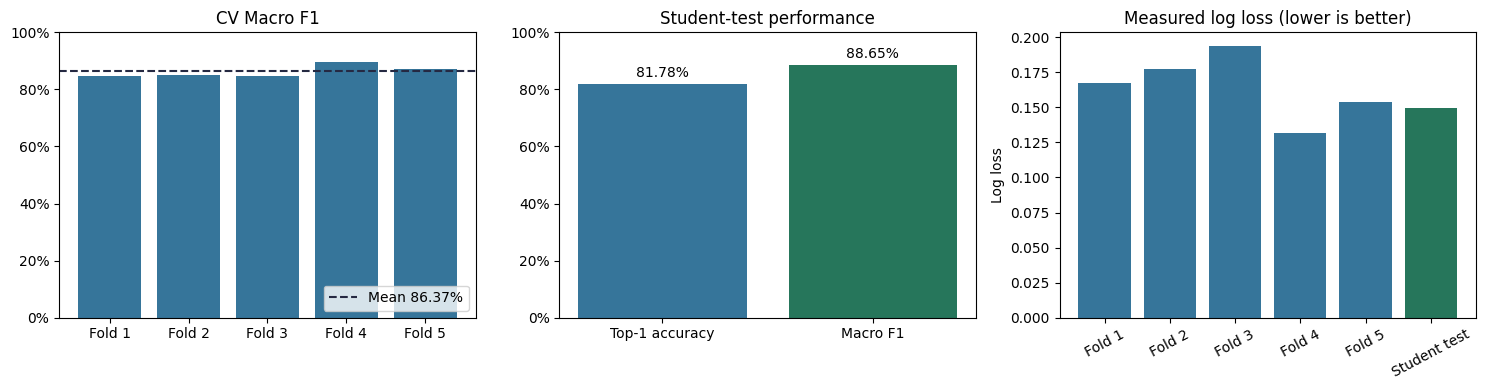

Epoch-wise training and validation loss curves do not apply to Extra Trees.
The log-loss bars use measured scores from the validation folds and student test.


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

cv_plot = cv_table.sort_values("fold").reset_index(drop=True)
cv_macro = cv_plot["macro_f1"].mean()
cv_log_loss = cv_plot["log_loss"].mean()
metric_summary = pd.DataFrame(
    {
        "Metric": ["CV Macro F1 (mean of 5 folds)", "Student-test Top-1 accuracy",
                   "Student-test Macro F1", "CV log loss (mean of 5 folds)",
                   "Student-test log loss"],
        "Result": [f"{cv_macro:.2%}", f"{test_scores['top1_accuracy']:.2%}",
                   f"{test_scores['macro_f1']:.2%}", f"{cv_log_loss:.4f}",
                   f"{test_scores['log_loss']:.4f}"],
    }
)
display(metric_summary)
display(cv_plot[["fold", "top1_accuracy", "macro_f1", "log_loss"]].assign(
    top1_accuracy=lambda f: f["top1_accuracy"].map("{:.2%}".format),
    macro_f1=lambda f: f["macro_f1"].map("{:.2%}".format),
    log_loss=lambda f: f["log_loss"].map("{:.4f}".format),
))

def show_and_save(fig, filename):
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fold_names = [f"Fold {i}" for i in cv_plot["fold"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.bar(fold_names, cv_plot["macro_f1"], color="#36759A")
ax.axhline(cv_macro, linestyle="--", color="#252942", label=f"Mean {cv_macro:.2%}")
ax.set(title="CV Macro F1", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower right")

ax = axes[1]
student_values = [test_scores["top1_accuracy"], test_scores["macro_f1"]]
bars = ax.bar(["Top-1 accuracy", "Macro F1"], student_values, color=["#36759A", "#26765B"])
ax.bar_label(bars, labels=[f"{value:.2%}" for value in student_values], padding=3)
ax.set(title="Student-test performance", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax = axes[2]
loss = cv_plot["log_loss"].tolist() + [test_scores["log_loss"]]
ax.bar(fold_names + ["Student test"], loss, color=["#36759A"] * 5 + ["#26765B"])
ax.set(title="Measured log loss (lower is better)", ylabel="Log loss")
ax.tick_params(axis="x", rotation=28)
show_and_save(fig, "extra_trees_shared6_metrics.png")

print("Epoch-wise training and validation loss curves do not apply to Extra Trees.")
print("The log-loss bars use measured scores from the validation folds and student test.")


### 6B. Candidate confusion matrices

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

def matrix_from_results(results):
    return np.array([[results["tn"], results["fp"]],
                     [results["fn"], results["tp"]]], dtype=int)

# Each training trip is held out once, so adding the fold counts gives
# the candidate-level out-of-fold confusion matrix.
cv_matrix = matrix_from_results(cv_plot[["tn", "fp", "fn", "tp"]].sum())
test_matrix = matrix_from_results(test_scores)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, matrix, title in zip(
    axes, (cv_matrix, test_matrix), ("Five CV folds pooled", "Student test"),
):
    ConfusionMatrixDisplay(matrix, display_labels=["Non-match", "Match"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",d",
    )
    ax.set_title(title)
fig.suptitle("Extra Trees candidate confusion matrices (threshold 0.50)")
show_and_save(fig, "extra_trees_shared6_confusion.png")


### 6C. Training-set EDA

EDA partition: 80 training trips. Counts below refer to the prepared features.


,Feature,Missing,Non-finite
0,distance_m,0,0
1,distance_rank,0,0
2,heading_difference_deg,0,0
3,projection_fraction,0,0
4,segment_length_m,0,0
5,displacement_m,0,0


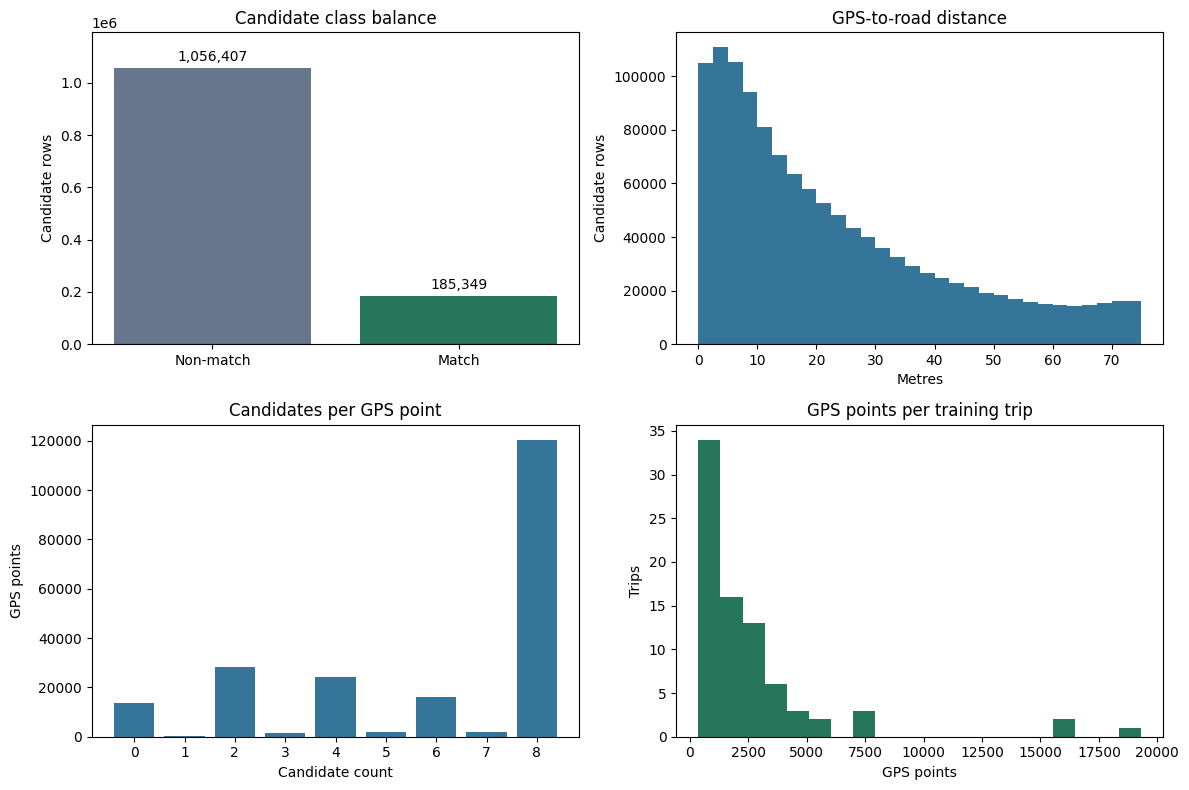

In [7]:
feature_summary = pd.DataFrame({
    "Feature": FEATURES,
    "Missing": np.isnan(train.X).sum(axis=0),
    "Non-finite": (~np.isfinite(train.X)).sum(axis=0),
})
print("EDA partition: 80 training trips. Counts below refer to the prepared features.")
display(feature_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
label_counts = np.bincount(train.y, minlength=2)
bars = ax.bar(["Non-match", "Match"], label_counts, color=["#66768C", "#26765B"])
ax.bar_label(bars, labels=[f"{n:,}" for n in label_counts], padding=3)
ax.set(title="Candidate class balance", ylabel="Candidate rows")
ax.margins(y=0.13)

ax = axes[0, 1]
distance = train.X[:, FEATURES.index("distance_m")]
ax.hist(distance, bins=np.linspace(0, 75, 31), color="#36759A")
ax.set(title="GPS-to-road distance", xlabel="Metres", ylabel="Candidate rows")

ax = axes[1, 0]
candidates_per_point = train.observations["candidate_count"].value_counts().sort_index()
ax.bar(candidates_per_point.index, candidates_per_point.values, color="#36759A")
ax.set(title="Candidates per GPS point", xlabel="Candidate count", ylabel="GPS points")
ax.set_xticks(range(9))

ax = axes[1, 1]
points_per_trip = train.observations.groupby("trip_id").size()
ax.hist(points_per_trip, bins=20, color="#26765B")
ax.set(title="GPS points per training trip", xlabel="GPS points", ylabel="Trips")
show_and_save(fig, "extra_trees_shared6_eda.png")


### 6D. Folium map of student-test trip 00000000

The map uses the GPS coordinates and predictions from this run. For the candidate road network, reference route and predicted road overlays, put the original `Student folder.zip` in Colab's Files panel or set `RAW_STUDENT_ZIP` to its path in Drive. The predicted layer displays Extra Trees' individual Top-1 road segments. A separate route decoder would be needed to assess connectivity.


In [11]:
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
from IPython.display import display

try:
    import folium
except ModuleNotFoundError:
    import subprocess
    import sys

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "folium"], check=True)
    import folium

TRIP_ID = "00000000"
SHOW_SATELLITE = True
RAW_DATA_ROOT = None  # Optional: path to the extracted Student folder.
RAW_STUDENT_ZIP = None  # Optional: path to Student folder.zip.

# Step 5 writes one Top-1 prediction per GPS observation.
prediction_path = RESULTS_DIR / "extra_trees_shared6_predictions.csv.gz"
if "test_predictions" in globals():
    predictions = test_predictions
elif prediction_path.is_file():
    predictions = pd.read_csv(prediction_path, dtype={"trip_id": str})
else:
    raise FileNotFoundError("Run Step 5 or restore the saved student-test predictions.")

observations = pd.read_csv(
    DATA_DIR / "student_test_observations.csv.gz",
    dtype={"trip_id": str},
    usecols=["trip_id", "observation_id", "timestamp", "latitude", "longitude"],
)
join_keys = ["trip_id", "observation_id"]
selection = predictions["trip_id"].eq(TRIP_ID)
trip = observations.loc[observations["trip_id"].eq(TRIP_ID)].merge(
    predictions.loc[selection, join_keys + ["predicted_arc_id", "top1_correct"]],
    on=join_keys, how="left", validate="one_to_one", indicator=True,
).sort_values("timestamp")
if trip.empty or not trip["_merge"].eq("both").all():
    raise ValueError(f"Missing observations or predictions for student-test trip {TRIP_ID}.")

trip = trip.loc[trip["latitude"].abs().le(90) & trip["longitude"].abs().le(180)]
if trip.empty:
    raise ValueError(f"No valid GPS coordinates for trip {TRIP_ID}.")

coordinates = trip[["latitude", "longitude"]].to_numpy()
trip_map = folium.Map(
    location=coordinates.mean(axis=0).tolist(),
    tiles=None, control_scale=True,
)
if SHOW_SATELLITE:
    folium.TileLayer(
        tiles="https://services.arcgisonline.com/ArcGIS/rest/services/"
              "World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, Vantor, Earthstar Geographics, and the GIS User Community",
        name="Esri World Imagery",
        max_zoom=19,
    ).add_to(trip_map)

# The satellite layer works without the original ZIP. The ZIP supplies road geometry.
trip_folders = [
    RUNTIME_DIR / "Student folder" / "student_test" / TRIP_ID,
    Path("/content/drive/MyDrive/PathSnap_ip/PathSnap_raw/Student folder/student_test") / TRIP_ID,
]
if RAW_DATA_ROOT is not None:
    trip_folders.insert(0, Path(RAW_DATA_ROOT) / "student_test" / TRIP_ID)
trip_folder = next((path for path in trip_folders if
                    (path / f"{TRIP_ID}.nodes").is_file() and
                    (path / f"{TRIP_ID}.arcs").is_file()), None)

zip_locations = [
    RUNTIME_DIR / "Student folder.zip",
    Path("/content/drive/MyDrive/PathSnap_ip/Student folder.zip"),
    Path("/content/drive/MyDrive/Student folder.zip"),
]
if RAW_STUDENT_ZIP is not None:
    zip_locations.insert(0, Path(RAW_STUDENT_ZIP))
raw_zip = next((path for path in zip_locations if path.is_file()), None)

nodes = arcs = reference_arcs = None
if trip_folder is not None:
    nodes = np.loadtxt(trip_folder / f"{TRIP_ID}.nodes", ndmin=2)
    arcs = np.loadtxt(trip_folder / f"{TRIP_ID}.arcs", dtype=int, ndmin=2)
    route_file = trip_folder / f"{TRIP_ID}.route"
    if route_file.is_file():
        reference_arcs = np.loadtxt(route_file, dtype=int, ndmin=1)
elif raw_zip is not None:
    with ZipFile(raw_zip) as archive:
        def read_trip_file(extension, dtype, required=True):
            suffix = f"/student_test/{TRIP_ID}/{TRIP_ID}.{extension}"
            matches = [name for name in archive.namelist() if f"/{name}".endswith(suffix)]
            if not matches and not required:
                return None
            if len(matches) != 1:
                raise ValueError(f"Expected one {TRIP_ID}.{extension} in {raw_zip.name}.")
            with archive.open(matches[0]) as stream:
                return np.loadtxt(stream, dtype=dtype, ndmin=2)

        nodes = read_trip_file("nodes", float)
        arcs = read_trip_file("arcs", int)
        reference_arcs = read_trip_file("route", int, required=False)

def draw_roads(segments, name, color, width, show=True):
    if not len(segments):
        return
    layer = folium.FeatureGroup(name=name, show=show).add_to(trip_map)
    folium.GeoJson(
        {"type": "Feature", "properties": {},
         "geometry": {"type": "MultiLineString", "coordinates": segments.tolist()}},
        style_function=lambda _: {"color": color, "weight": width, "opacity": 0.9},
    ).add_to(layer)

if nodes is not None:
    # Draw nearby dataset streets as an optional background for restricted networks.
    roads = nodes[np.unique(np.sort(arcs, axis=1), axis=0)]
    lon_lat = coordinates[:, ::-1]
    padding = np.maximum(np.ptp(lon_lat, axis=0) * 0.10, 0.005)
    west_south, east_north = lon_lat.min(axis=0) - padding, lon_lat.max(axis=0) + padding
    nearby = ((roads.max(axis=1) >= west_south) & (roads.min(axis=1) <= east_north)).all(axis=1)
    draw_roads(roads[nearby], "Dataset streets", "#9EA8B0", 2, show=not SHOW_SATELLITE)

    predicted_ids = np.unique(trip["predicted_arc_id"].dropna().to_numpy(dtype=int))
    if (predicted_ids < 0).any() or (predicted_ids >= len(arcs)).any():
        raise ValueError("Prediction arc IDs do not match the original road network.")
    if reference_arcs is not None:
        draw_roads(nodes[arcs[np.unique(reference_arcs)]], "Reference route", "#7CE848", 6)
    draw_roads(nodes[arcs[predicted_ids]], "Extra Trees Top-1 segments", "#25D9F7", 4)
else:
    print("Add Student folder.zip for the optional street and road-segment layers.")

gps_layer = folium.FeatureGroup(name="Recorded GPS trace").add_to(trip_map)
folium.PolyLine(coordinates.tolist(), color="#F65252", weight=3, opacity=0.9).add_to(gps_layer)
for point, name in ((coordinates[0], "Start"), (coordinates[-1], "End")):
    folium.CircleMarker(point.tolist(), radius=6, color="#FFFFFF", fill=True,
                        fill_color="#EF4343", fill_opacity=1, tooltip=name).add_to(gps_layer)

is_match = trip["top1_correct"].eq(True)
miss_layer = folium.FeatureGroup(name="Top-1 misses", show=False).add_to(trip_map)
misses = trip.loc[~is_match]
stride = max(1, (len(misses) + 499) // 500)
for point in misses.iloc[::stride].itertuples(index=False):
    folium.CircleMarker(
        [point.latitude, point.longitude], radius=3, color="#FFA943",
        fill=True, fill_opacity=0.85, tooltip=f"GPS point {point.observation_id}",
    ).add_to(miss_layer)

trip_map.fit_bounds([coordinates.min(axis=0).tolist(), coordinates.max(axis=0).tolist()],
                    max_zoom=16, padding=(18, 18))
folium.LayerControl(collapsed=False).add_to(trip_map)
map_path = RESULTS_DIR / f"extra_trees_trip_{TRIP_ID}.html"
trip_map.save(str(map_path))
print(f"Trip {TRIP_ID} | {len(trip):,} GPS points | Top-1 {is_match.mean():.2%}")
print(f"Saved {map_path.name}.")
display(trip_map)


Add Student folder.zip for the optional street and road-segment layers.
Trip 00000000 | 2,503 GPS points | Top-1 91.81%
Saved extra_trees_trip_00000000.html.


## 7. Download the result bundle

The ZIP contains the fitted pipeline, metrics, predictions, configuration, figures, and Folium HTML map.


In [12]:
from google.colab import files

output_zip = shutil.make_archive(
    str(WORK_DIR / "pathsnap_extra_trees_shared6_results"), "zip", RESULTS_DIR
)
print(f"Results ZIP: {output_zip}")
files.download(output_zip)


Results ZIP: /content/pathsnap_shared6_extra_trees/pathsnap_extra_trees_shared6_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>